### **DEPENDENCIES, DATA & SETUP**

<h4><b>Imports</b></h4>

In [15]:
import polars as pl
from matplotlib import pyplot as plt
import seaborn as sns
import pycountry

<h4><b>Loading</b></h4>

In [2]:
# Load the CSV file into df
df = pl.read_csv("../data/data.csv")

# View available variables and their data types
pl.Config.set_tbl_rows(-1)
pl.DataFrame(
    {
        "column": df.columns,
        "data_type": [str(dt) for dt in df.dtypes],
        "null_count": df.null_count().row(0),
        "non_null_count": [df.height - nc for nc in df.null_count().row(0)],
    }
)

column,data_type,null_count,non_null_count
str,str,i64,i64
"""EPOCH_SECONDS""","""Int64""",0,10000000
"""CURRENCY_CODE""","""String""",0,10000000
"""USD_AMOUNT""","""Float64""",0,10000000
"""ORDERING_BIC8""","""String""",0,10000000
"""BENEFICIARY_BIC8""","""String""",0,10000000
"""BIC8_PATH""","""String""",0,10000000
"""TOTAL_DURATION""","""Int64""",0,10000000
"""CONTINUITY_QFLAG""","""Boolean""",0,10000000
"""CURRENCY_CONVERSION_COUNT""","""Int64""",0,10000000


In [3]:
pl.Config.set_tbl_rows(10)

polars.config.Config

<h4><b>Exploring/Viewing</b></h4>

In [4]:
# View the head of the DataFrame
df.head()

EPOCH_SECONDS,CURRENCY_CODE,USD_AMOUNT,ORDERING_BIC8,BENEFICIARY_BIC8,BIC8_PATH,TOTAL_DURATION,CONTINUITY_QFLAG,CURRENCY_CONVERSION_COUNT,PARTICIPANT_COUNT,TRANSACTION_TYPE_CODE,ORDERING_ACCOUNT,BENEFICIARY_ACCOUNT,ORDERING_DETAILS,ORDERING_TOKENS,BENEFICIARY_DETAILS,BENEFICIARY_TOKENS,ORDERING_TYPE,BENEFICIARY_TYPE,ANOMALY_TYPE
i64,str,f64,str,str,str,i64,bool,i64,i64,str,str,str,str,str,str,str,str,str,str
1685363344,"""USD""",500.0,"""0621US30""","""0219US30""","""0621US30;0219US30""",4,true,0,2,"""Direct""","""_FAKE_00.-0/0092Y9262""","""_FAKE_0009559K28N""","""/00.-0/0092Y9262 SCHULTZ PLC 3…","""/<chr:99.-9/9999A9999> <line_b…","""/0009559K28N S MRDHAA 66 SIRAJ…","""/<chr:9999999A99A> <line_break…","""B""","""C""",null
1686659145,"""TRY""",1390.34,"""0024TRI0""","""0380CNB0""","""0024TRI0;0380CNB0""",396,true,1,2,"""Direct""","""_FAKE_TR53002400000000890222""","""_FAKE_0000000008A79136""","""/TR53002400000000890222 CALIK …","""/<iban:22> <line_break:35><bus…","""//0000000008A79136 GUI LAN XI…","""/<separator:/><chr:9999999999A…","""B""","""C""",null
1688492312,"""GBP""",3972.37,"""0007JEH0""","""0295GB20""","""0007JEH0;0295GB20""",3,true,0,2,"""Direct""","""_FAKE_00 000 000B0623 133W""","""_FAKE_GB30029500000000623158""","""/00 000 000B0623 133W 1/GORDON…","""/<chr:99 999 999A9999 999A> <o…","""/GB30029500000000623158 W GUI …","""/<iban:22> <chr:A> <last_name:…","""B""","""C""",null
1684465569,"""SGD""",1920.69,"""0203SGS0""","""0037DEF0""","""0203SGS0;0405US30;0037DEF0""",4341,true,2,3,"""Indirect""","""_FAKE_00000 F00/08/57/6/40""","""_FAKE_DE49003700000000292310""","""/00000 F00/08/57/6/40 PERUM WA…","""/<chr:99999 A99/99/99/9/99> <l…","""/DE49003700000000292310 M ALBA…","""/<iban:22> <other_words:6> <la…","""B""","""C""",null
1686000776,"""EUR""",22130.99,"""0017DEF0""","""0087ZAJ0""","""0017DEF0;0087ZAJ0""",20,true,1,2,"""Direct""","""_FAKE_DE13001700000000291498""","""_FAKE_ 0000000.00099.3989""","""/DE13001700000000291498 KREUSE…","""/<iban:22> <line_break:35><bus…","""/ 0000000.00099.3989 MHWRSZN Y…","""/<chr: 9999999.99999.9999> <bu…","""B""","""B""",null


<h4><b>Edit Data Type</b></h4>
For good measure

In [5]:
df = df.with_columns(
    [
        pl.col("CURRENCY_CODE").cast(pl.Categorical),
        pl.col("TRANSACTION_TYPE_CODE").cast(pl.Categorical),
        pl.col("ORDERING_TYPE").cast(pl.Categorical),
        pl.col("BENEFICIARY_TYPE").cast(pl.Categorical),
        pl.col("ANOMALY_TYPE").cast(pl.Categorical),
    ]
)

<br>
<br>
<br>
<br>
<br>

# <u>**EXPLORATORY DATA ANALYSIS**</u>

<hr>

## **PART A: Numerical Analysis**

### 1. Bivariate association between numerical variables

The script below shows a correlation matrix. The selection metric used is the **Pearson correlation coefficient ($r$)**.

In [10]:
numeric_cols = df.select(pl.selectors.numeric()).columns

with pl.Config(tbl_cols=-1, tbl_rows=-1):
    display(
        df.select(pl.selectors.numeric())
        .corr()
        .with_columns(pl.selectors.float().round(5))
        .insert_column(0, pl.Series("variable", numeric_cols))
    )

variable,EPOCH_SECONDS,USD_AMOUNT,TOTAL_DURATION,CURRENCY_CONVERSION_COUNT,PARTICIPANT_COUNT
str,f64,f64,f64,f64,f64
"""EPOCH_SECONDS""",1.0,0.00041,-0.00056,-0.00068,-0.00005
"""USD_AMOUNT""",0.00041,1.0,-0.00018,-0.00039,-0.00021
"""TOTAL_DURATION""",-0.00056,-0.00018,1.0,0.12967,0.14933
"""CURRENCY_CONVERSION_COUNT""",-0.00068,-0.00039,0.12967,1.0,0.86876
"""PARTICIPANT_COUNT""",-0.00005,-0.00021,0.14933,0.86876,1.0


The relationship between `PARTICIPANT_COUNT` and `CURRENCY_CONVERSION_COUNT` is somewhat explainable, since we could hypothesise that as the number of participants increases, the likelihood of increased currency conversions also increase. Thus, we will not further explore it yet.  

Likewise, the weak relationship between `TOTAL DURATION` and each of `PARTICIPANT_COUNT` and `CURRENCY_CONVERSION_COUNT` is also explainable, since the more operations a transaction takes, we could hypothesise that the total duration would increase accordingly. It is worth noting, however, that the correlation is extremely weak, suggesting an alternative association.  

Other associations appear to be insignificant. But to confirm our suspicion, let's visualise their relationship using scatter plots. Each scatter plot **shows a sample only**, not the entire dataset. 

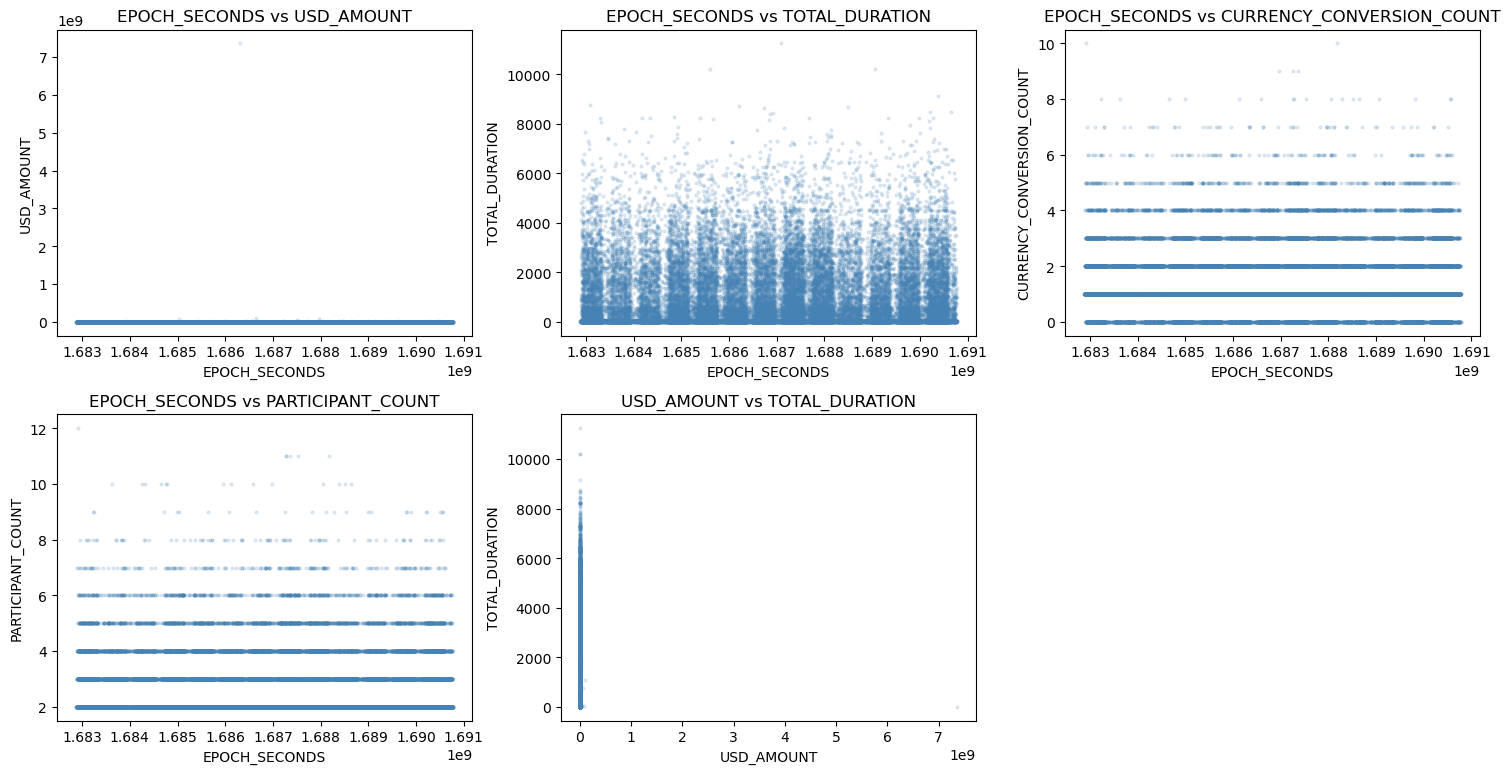

In [16]:
# Sample 50,000 rows to prevent overplotting and RAM spikes
sampled_df = df.select([
    "USD_AMOUNT", 
    "TOTAL_DURATION", 
    "CURRENCY_CONVERSION_COUNT", 
    "PARTICIPANT_COUNT", 
    "EPOCH_SECONDS"
]).sample(n=50000, seed=42).to_pandas()

# Define the 5 specific pairs you want to inspect
pairs = [
    ("EPOCH_SECONDS", "USD_AMOUNT"),
    ("EPOCH_SECONDS", "TOTAL_DURATION"),
    ("EPOCH_SECONDS", "CURRENCY_CONVERSION_COUNT"),
    ("EPOCH_SECONDS", "PARTICIPANT_COUNT"),
    ("USD_AMOUNT", "TOTAL_DURATION")
]

# Set up a 2-row, 3-column subplot grid
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

for i, (x_col, y_col) in enumerate(pairs):
    ax = axes[i]
    ax.scatter(
        sampled_df[x_col], 
        sampled_df[y_col], 
        alpha=0.15,  # Low alpha helps reveal density where points overlap
        s=4,         # Small marker size
        color="steelblue"
    )
    ax.set_title(f"{x_col} vs {y_col}")
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

# Hide the 6th empty subplot box
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

The following is to plot violin plots for each of `PARTICIPANT_COUNT` and `CURRENCY_CONVERSION_COUNT` vs `TOTAL DURATION`. This is to help identify any alternative relationship between these variables. 

We suspect: there exist a non-linear relationship between each of `PARTICIPANT_COUNT` and `CURRENCY_CONVERSION_COUNT` vs `TOTAL DURATION`.

/var/folders/7v/5nnc6yf94sx8fj4gkl8_6l3c0000gn/T/ipykernel_36478/3121343688.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/7v/5nnc6yf94sx8fj4gkl8_6l3c0000gn/T/ipykernel_36478/3121343688.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


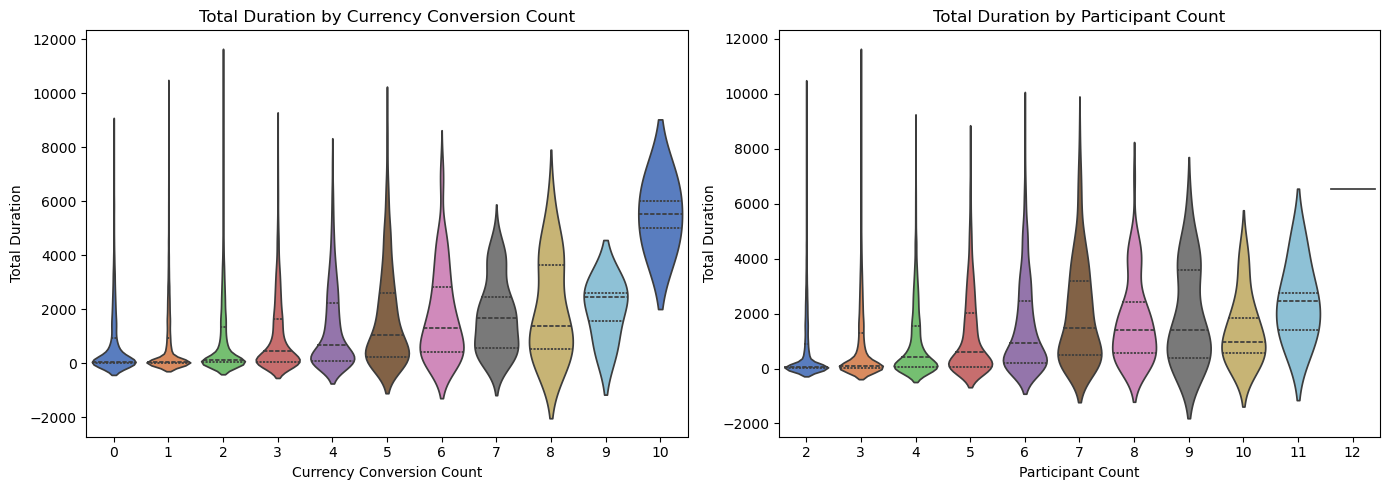

In [17]:
# Ensure count columns are treated as categorical/discrete integers for grouping
violin_data = sampled_df.copy()
violin_data["CURRENCY_CONVERSION_COUNT"] = violin_data["CURRENCY_CONVERSION_COUNT"].astype(int)
violin_data["PARTICIPANT_COUNT"] = violin_data["PARTICIPANT_COUNT"].astype(int)

# Create a 2-panel figure comparing both counts against TOTAL_DURATION
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Plot 1: Currency Conversion Count vs Total Duration
sns.violinplot(
    data=violin_data, 
    x="CURRENCY_CONVERSION_COUNT", 
    y="TOTAL_DURATION", 
    ax=axes[0], 
    palette="muted",
    inner="quartile"
)
axes[0].set_title("Total Duration by Currency Conversion Count")
axes[0].set_xlabel("Currency Conversion Count")
axes[0].set_ylabel("Total Duration")

# Plot 2: Participant Count vs Total Duration
sns.violinplot(
    data=violin_data, 
    x="PARTICIPANT_COUNT", 
    y="TOTAL_DURATION", 
    ax=axes[1], 
    palette="muted",
    inner="quartile"
)
axes[1].set_title("Total Duration by Participant Count")
axes[1].set_xlabel("Participant Count")
axes[1].set_ylabel("Total Duration")

plt.tight_layout()
plt.show()

The relationship between `CURRENCY_CONVERSION_COUNT` and `TOTAL_DURATION` reveals a pronounced non-linear escalation, approximating a quadratic or exponential curve, as conversion legs increase. As the count rises, the distribution's median usually shifts upward, and its density profile morphs from a base-heavy "pendulum" into a bulging "lemon." This expanding variance suggests that multi-leg foreign exchange routing triggers disproportionate operational friction (likely driven by computational problems like combinatorial cross-rate matrix lookups, complex routing permutations, or multi-step compliance validations) that introduce heavy computational latency.

In contrast, `PARTICIPANT_COUNT` exhibits a much milder association with `TOTAL_DURATION`. While higher participant numbers introduce a slight upward drift, the median trajectory appear flatter than the previous and the overall distribution shape shifts far less dramatically. This muted impact implies that scaling the number of stakeholders or secondary accounts is handled via parallelized database insertions, broadcasting, or standard list processing rather than intensive cross-referencing, effectively insulating the core processing timeline from severe bottlenecks.

In a nutshell, there appears to be a non-linear association between each of `PARTICIPANT_COUNT` and `CURRENCY_CONVERSION_COUNT` vs `TOTAL DURATION`.

### 2. Univariate numerical variables frequency distribution

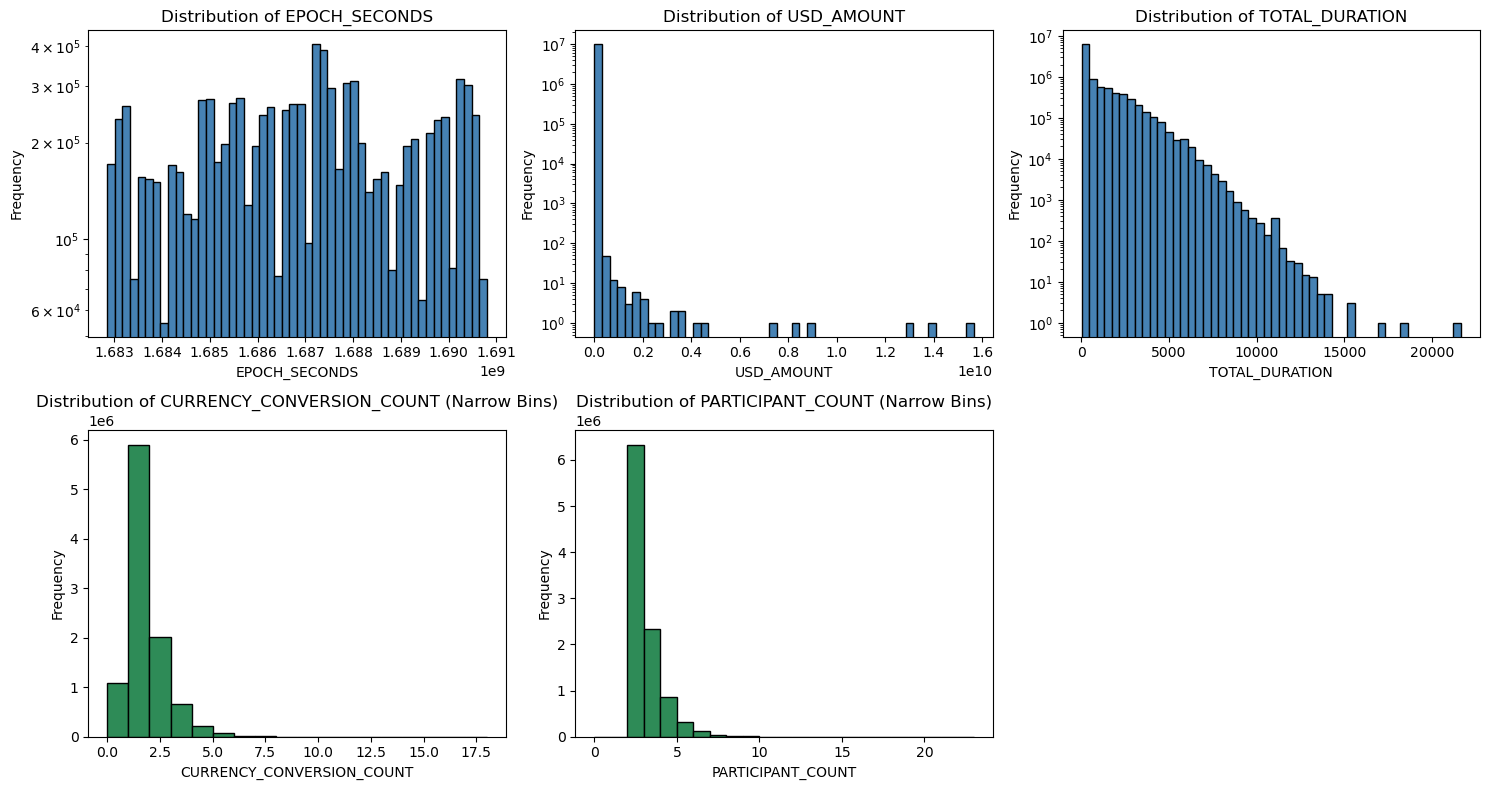

In [12]:
# 1. Pull only the numeric subset into pandas for plotting
pd_subset = df.select(numeric_cols).to_pandas()

# 2. Set up a 2-row, 3-column subplot grid
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    
    # Check if the column is one of the count variables requiring narrower/discrete intervals
    if col in ["CURRENCY_CONVERSION_COUNT", "PARTICIPANT_COUNT"]:
        # Find the max value to set tight integer bin boundaries (narrowed factor/intervals)
        max_val = int(pd_subset[col].max())
        bins = range(0, max_val + 2) if max_val < 100 else 50
        
        ax.hist(pd_subset[col].dropna(), bins=bins, color="seagreen", edgecolor="black")
        ax.set_title(f"Distribution of {col} (Narrow Bins)")
    else:
        # Standard 50-bin histogram for USD_AMOUNT, EPOCH_SECONDS, and TOTAL_DURATION
        ax.hist(pd_subset[col].dropna(), bins=50, color="steelblue", edgecolor="black")
        ax.set_title(f"Distribution of {col}")
        ax.set_yscale("log") # Log scale kept for heavy-tailed financial/duration variables

    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

# Hide the 6th empty subplot box since there are only 5 features
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Visualisations reveal various things about the distributions of the 5 numerical variables of the dataset.  

To begin with, `EPOCH_SECONDS` appear roughly uniformly distributed. This could be explained by the fact that transactions could be happening consistently over the years.  

The wedge-shaped histogram for `TOTAL_DURATION` could be explained as such:  
* The spike at the leftmost end of the graph represents straight-through processing (STP); i.e., digital transactions that clear immediately, with execution time limited only by baseline network latency or server CPU speed.
* A linear downward slope implies that as transactions encounter friction (e.g., database locks, queue congestion, or routing hops), the likelihood of a transaction lingering at any specific extra second decreases at a steady, uniform rate.

Both distributions of `CURRENCY_CONVERSION_COUNT` and `PARTICIPANT_COUNT` exhibit notable right-skewness. However, distinguishing between an exponential decay and a power-law model requires further diagnostic validation—such as log-log plot analysis—before drawing definitive conclusions about the underlying generative process.

Finally, `USD_AMOUNT` appears to have many gaps between bars. To make the distribution appear clearer, let's remove it's outliers to see a clearer distribution. 

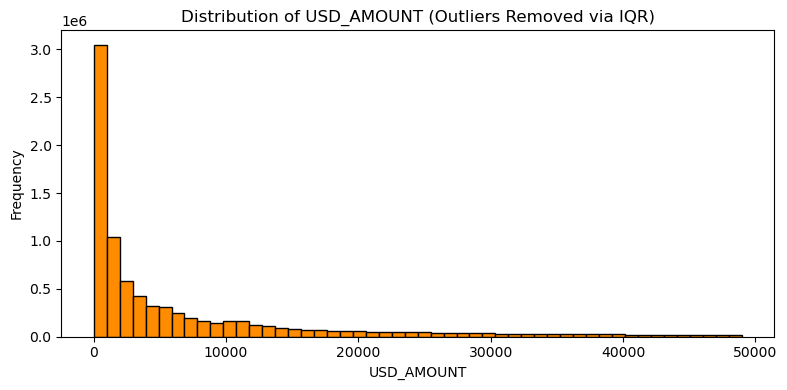

In [13]:
# 1. Filter out outliers for USD_AMOUNT on the fly without altering the original 'df'
# We compute the Q1 and Q3 bounds first or apply a standard quantile filter
q25 = df.select(pl.col("USD_AMOUNT").quantile(0.25)).item()
q75 = df.select(pl.col("USD_AMOUNT").quantile(0.75)).item()
iqr = q75 - q25

lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# 2. Extract only the filtered USD_AMOUNT series into pandas (minimal memory footprint)
clean_usd = (
    df.filter(
        (pl.col("USD_AMOUNT") >= lower_bound) & 
        (pl.col("USD_AMOUNT") <= upper_bound)
    )
    .select("USD_AMOUNT")
    .to_series()
    .to_pandas()
)

# 3. Plot the new histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(clean_usd.dropna(), bins=50, color="darkorange", edgecolor="black")
ax.set_title("Distribution of USD_AMOUNT (Outliers Removed via IQR)")
ax.set_xlabel("USD_AMOUNT")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

From the histogram above, it's clear that `USD_AMOUNT` also exhibits characteristics of an exponential distribution or power law distribution. More analysis and modelling is necessary to better understand the properties of this variable. 

# 

<hr>

## **PART B: Categorical Analysis**

### 1. Univariate Frequency Analysis

In this analysis, we intend to display a frequency table of each of the following select variables:
* `ANOMALY_TYPE`
* `TRANSACTION_TYPE_CODE`
* `ORDERING_TYPE`
* `BENEFICIARY_TYPE`
* `CURRENCY_CODE`
* `CONTINUITY_QFLAG`

This is intended to help us figure out how these variables are roughly distributed. 

In [20]:
# Define the categorical columns to analyze
cat_cols = [
    "ANOMALY_TYPE",
    "TRANSACTION_TYPE_CODE",
    "ORDERING_TYPE",
    "BENEFICIARY_TYPE",
    "CURRENCY_CODE",
    "CONTINUITY_QFLAG"
]

# Total row count for percentage calculations
total_rows = df.height

# Loop through and generate frequency/dominance tables
frequency_tables = {}

for col in cat_cols:
    # Group by category, count occurrences, calculate percentage share, and sort descending
    freq_df = (
        df.select(col)
        .group_by(col)
        .len(name="count")
        .with_columns(
            (pl.col("count") / total_rows * 100).alias("share_pct").round(2)
        )
        .sort("count", descending=True)
    )
    frequency_tables[col] = freq_df

# Display them cleanly in your notebook
with pl.Config(tbl_cols=-1, tbl_rows=20):
    for col, freq_df in frequency_tables.items( ):
        print(f"==============================")
        print(f" Frequency Table: {col}")
        print(f"==============================")
        display(freq_df)
        print("\n")

 Frequency Table: ANOMALY_TYPE


ANOMALY_TYPE,count,share_pct
cat,u32,f64
null,9992994,99.93
"""ROMANCE_SCAM""",2476,0.02
"""FAT_FINGER_MISTAKE""",1940,0.02
"""CEO_SCAM""",945,0.01
"""DUPLICATE_PAYMENT""",679,0.01
"""ACCOUNT_REPLACEMENT_SCAM""",649,0.01
"""CUSTOMER_RECALL""",317,0.0




 Frequency Table: TRANSACTION_TYPE_CODE


TRANSACTION_TYPE_CODE,count,share_pct
cat,u32,f64
"""Direct""",6323280,63.23
"""Indirect""",3260758,32.61
"""Covered""",415962,4.16




 Frequency Table: ORDERING_TYPE


ORDERING_TYPE,count,share_pct
cat,u32,f64
"""B""",7874637,78.75
"""C""",2125363,21.25


... (2 outputs left out)



 Frequency Table: CURRENCY_CODE


CURRENCY_CODE,count,share_pct
cat,u32,f64
"""EUR""",3208288,32.08
"""USD""",1702991,17.03
"""GBP""",873781,8.74
"""CHF""",803898,8.04
"""SGD""",367648,3.68
"""CNY""",324963,3.25
"""HKD""",197458,1.97
"""JPY""",184251,1.84
"""AUD""",166877,1.67




 Frequency Table: CONTINUITY_QFLAG


CONTINUITY_QFLAG,count,share_pct
bool,u32,f64
true,9232796,92.33
false,767204,7.67


From this analysis, various implicatins can be made. 

1. `ANOMALY_TYPE`  
   The overwhelming majority (>99.9%) of transactions are anomaly-free. Of the remaining anomalies, the ones that require most attention are `ROMANCE_SCAM`s and `FAT_FINGER_MISTAKE`s. 
   
2. `TRANSACTION_TYPE_CODE`  
   Most transactions (\~63%) are direct sender-to-recipient transactions. About one third of all transactions are not direct transactions. A minority (\~4%) of transactions are cover-payment-style routes. 
   
3. `ORDERING_TYPE`  
   About 4 out of every 5 ordering are businesses. The rest are consumers. 

4. `BENEFICIARY_TYPE`  
   Approximately 71% of beneficiaries are consumers, the rest are businesses. 

5. `CURRENCY_CODE`  
   The top 3 currencies that transactions were made in are the following:  
   **1st** - EUR (32.08%)  
   **2nd** - USD (17.03%)  
   **3rd** - GBP (8.74%)  

   The 3 least transacted currencies are the following:  
   **1st** - SVC (4 transactions)  
   **2nd** - FKP (5 transactions)  
   **3rd** - ERN (15 transactions)  

6. `CONTINUITY_QFLAG`  
   The majority (\~92%) of transaction paths are succinct enough to not be hidden ("...")

### 2. Multivariate Relationship Identification

In this section, we will be analysing potential relationships and percentage breakdowns between categorical variables to get a better picture of the truth about these transactions. 

In [22]:
# Anomaly Type vs. Ordering Type (Consumer vs. Business Sender)
anomaly_vs_ordering = (
    df.group_by(["ANOMALY_TYPE", "ORDERING_TYPE"])
    .len(name="count")
    .pivot(index="ANOMALY_TYPE", on="ORDERING_TYPE", values="count")
    .fill_null(0)
)

# Anomaly Type vs. Transaction Type Code (Direct, Indirect, Covered)
anomaly_vs_trx = (
    df.group_by(["ANOMALY_TYPE", "TRANSACTION_TYPE_CODE"])
    .len(name="count")
    .pivot(index="ANOMALY_TYPE", on="TRANSACTION_TYPE_CODE", values="count")
    .fill_null(0)
)

# Ecosystem Matrix: Ordering Type vs. Beneficiary Type (The 2x2 Channel Split)
ecosystem_matrix = (
    df.group_by(["ORDERING_TYPE", "BENEFICIARY_TYPE"])
    .len(name="count")
    .pivot(index="ORDERING_TYPE", on="BENEFICIARY_TYPE", values="count")
    .fill_null(0)
)

# Display the results cleanly in your Jupyter notebook
with pl.Config(tbl_cols=-1):
    print("=== 1. Anomaly Type by Sender Type (Ordering) ===")
    display(anomaly_vs_ordering)
    
    print("\n=== 2. Anomaly Type by Routing Structure (Transaction Type) ===")
    display(anomaly_vs_trx)
    
    print("\n=== 3. Ecosystem Matrix (Ordering vs. Beneficiary Type) ===")
    display(ecosystem_matrix)

=== 1. Anomaly Type by Sender Type (Ordering) ===


ANOMALY_TYPE,B,C
cat,u32,u32
null,7870850,2122144
"""FAT_FINGER_MISTAKE""",1543,397
"""ROMANCE_SCAM""",0,2476
"""ACCOUNT_REPLACEMENT_SCAM""",508,141
"""CEO_SCAM""",945,0
"""DUPLICATE_PAYMENT""",545,134
"""CUSTOMER_RECALL""",246,71



=== 2. Anomaly Type by Routing Structure (Transaction Type) ===


ANOMALY_TYPE,Direct,Indirect,Covered
cat,u32,u32,u32
null,6318885,3258294,415815
"""FAT_FINGER_MISTAKE""",1271,581,88
"""ROMANCE_SCAM""",1494,979,3
"""ACCOUNT_REPLACEMENT_SCAM""",443,203,3
"""CEO_SCAM""",592,346,7
"""DUPLICATE_PAYMENT""",408,240,31
"""CUSTOMER_RECALL""",187,115,15



=== 3. Ecosystem Matrix (Ordering vs. Beneficiary Type) ===


ORDERING_TYPE,C,B
cat,u32,u32
"""B""",5603692,2270945
"""C""",1514758,610605


The anomaly distribution maps directly to expected behavioral profiles. On the one hand, Romance Scams concentrate almost exclusively within the Consumer (C) segment, reflecting peer-to-peer manipulation tactics. On the other hand, CEO Scams isolate almost entirely within the Business (B) segment, targeting corporate finance workflows through spoofed executive directives. Meanwhile, operational errors like Fat Finger Mistakes and Duplicate Payments span both segments, though heavily anchored in high-volume institutional or corporate back-offices.  

Across the baseline (null/no anomalies) and routine errors like Fat Finger Mistakes, Direct routing dominates overwhelmingly. This aligns with expectations: standard retail or simple direct-entry transactions rarely require multi-hop intermediary networks. Conversely, institutional or cross-border-heavy vectors—such as corporate CEO Scams and complex fraud types—tend to show a notable shift or higher relative representation in Indirect (intermediary-routed) or Covered payment channels. Because corporate and cross-border transactions frequently rely on correspondent banking networks and multi-step payment instructions, fraudsters targeting these channels often leverage or exploit the inherent opacity of indirect routing structures.  

The dataset is overwhelmingly corporate-driven (~80% originating from businesses), split across four corridors:
* B → C (5.60M / ~56%): The dominant operational backbone (payroll, merchant payouts, disbursements), providing a massive volume pool for masking anomalies.
* B → B (2.27M / ~23%): The corporate supply chain and B2B invoicing anchor.
* C → C (1.51M / ~15%): The peer-to-peer retail and remittance corridor (primary vector for consumer scams).
* C → B (0.61M / ~6%): The smallest segment, capturing consumer bill payments and purchases.  

Because commercial senders dominate, anomaly and risk models must normalize against these structural baselines to prevent skewed scoring and high false-positive rates.

## **PART C: Misc. Analysis**